# Visualização das séries de modelagem

Lê `dados/processados/series_diarias.csv` (gerado por `preparar_series.py`), que é a
mesma fonte usada pelos modelos. Assim, o que aparece aqui é exatamente o que o ARIMA e
os próximos modelos recebem.

- **Núcleo** (comparação principal, bidirecional): Alambari, Boituva, Bloqueio de
  Boituva, Porto Feliz.
- **Caso Sorocaba** (separado, unidirecional — o pedágio só cobra quem entra na
  cidade, então mede metade do fluxo e não pode ser comparado diretamente com o
  núcleo).

**Como usar:** abrir no Jupyter ou VS Code e rodar as células em ordem (menu *Run All*).


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import config

plt.rcParams["figure.dpi"] = 100

series = pd.read_csv("dados/processados/series_diarias.csv", parse_dates=["DATA"])
PRACAS = config.PRACAS_NUCLEO + config.PRACAS_CASO_SOROCABA

series.groupby(["GRUPO", "PRACA", "DIRECIONALIDADE"]).agg(
    inicio=("DATA", "min"), fim=("DATA", "max"),
    dias_ok=("STATUS", lambda s: (s == "OK").sum()),
    dias_ausentes=("STATUS", lambda s: (s == "AUSENTE").sum()),
    dias_invalidados=("STATUS", lambda s: (s == "INVALIDADO").sum()),
    media_diaria=("VOLUME_TOTAL", "mean"),
).round(0)

/tmp/ipykernel_228/1250325384.py:17: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).round(0)


inicio        fim  \
GRUPO         PRACA               DIRECIONALIDADE                         
CASO_SOROCABA SOROCABA            UNIDIRECIONAL   2020-01-01 2026-07-31   
NUCLEO        ALAMBARI            BIDIRECIONAL    2020-01-01 2026-07-31   
              BLOQUEIO DE BOITUVA BIDIRECIONAL    2020-01-01 2026-07-31   
              BOITUVA             BIDIRECIONAL    2020-01-01 2026-07-31   
              PORTO FELIZ         BIDIRECIONAL    2020-01-01 2026-07-31   

                                                   dias_ok  dias_ausentes  \
GRUPO         PRACA               DIRECIONALIDADE                           
CASO_SOROCABA SOROCABA            UNIDIRECIONAL       2337             67   
NUCLEO        ALAMBARI            BIDIRECIONAL        2404              0   
              BLOQUEIO DE BOITUVA BIDIRECIONAL        2284             89   
              BOITUVA             BIDIRECIONAL        2284             89   
              PORTO FELIZ         BIDIRECIONAL        2284             89   

                                                   dias_invalidados  \
GRUPO         PRACA               DIRECIONALIDADE                     
CASO_SOROCABA SOROCABA            UNIDIRECIONAL                   0   
NUCLEO        ALAMBARI            BIDIRECIONAL                    0   
              BLOQUEIO DE BOITUVA BIDIRECIONAL                   31   
              BOITUVA             BIDIRECIONAL                   31   
              PORTO FELIZ         BIDIRECIONAL                   31   

                                                   media_diaria  
GRUPO         PRACA               DIRECIONALIDADE                
CASO_SOROCABA SOROCABA            UNIDIRECIONAL         27668.0  
NUCLEO        ALAMBARI            BIDIRECIONAL          12618.0  
              BLOQUEIO DE BOITUVA BIDIRECIONAL           5413.0  
              BOITUVA             BIDIRECIONAL          28591.0  
              PORTO FELIZ         BIDIRECIONAL           6251.0

## 1. Série temporal completa

Faixas sombreadas: **vermelho** = dia sem registro no arquivo da ARTESP; **laranja** =
dado descartado por ser inválido (out/2022 no lote L13-Colinas, volume ~1,85x o
normal). A linha tracejada marca o início do período de modelagem (2021-01-01) — 2020
fica de fora por causa da pandemia.

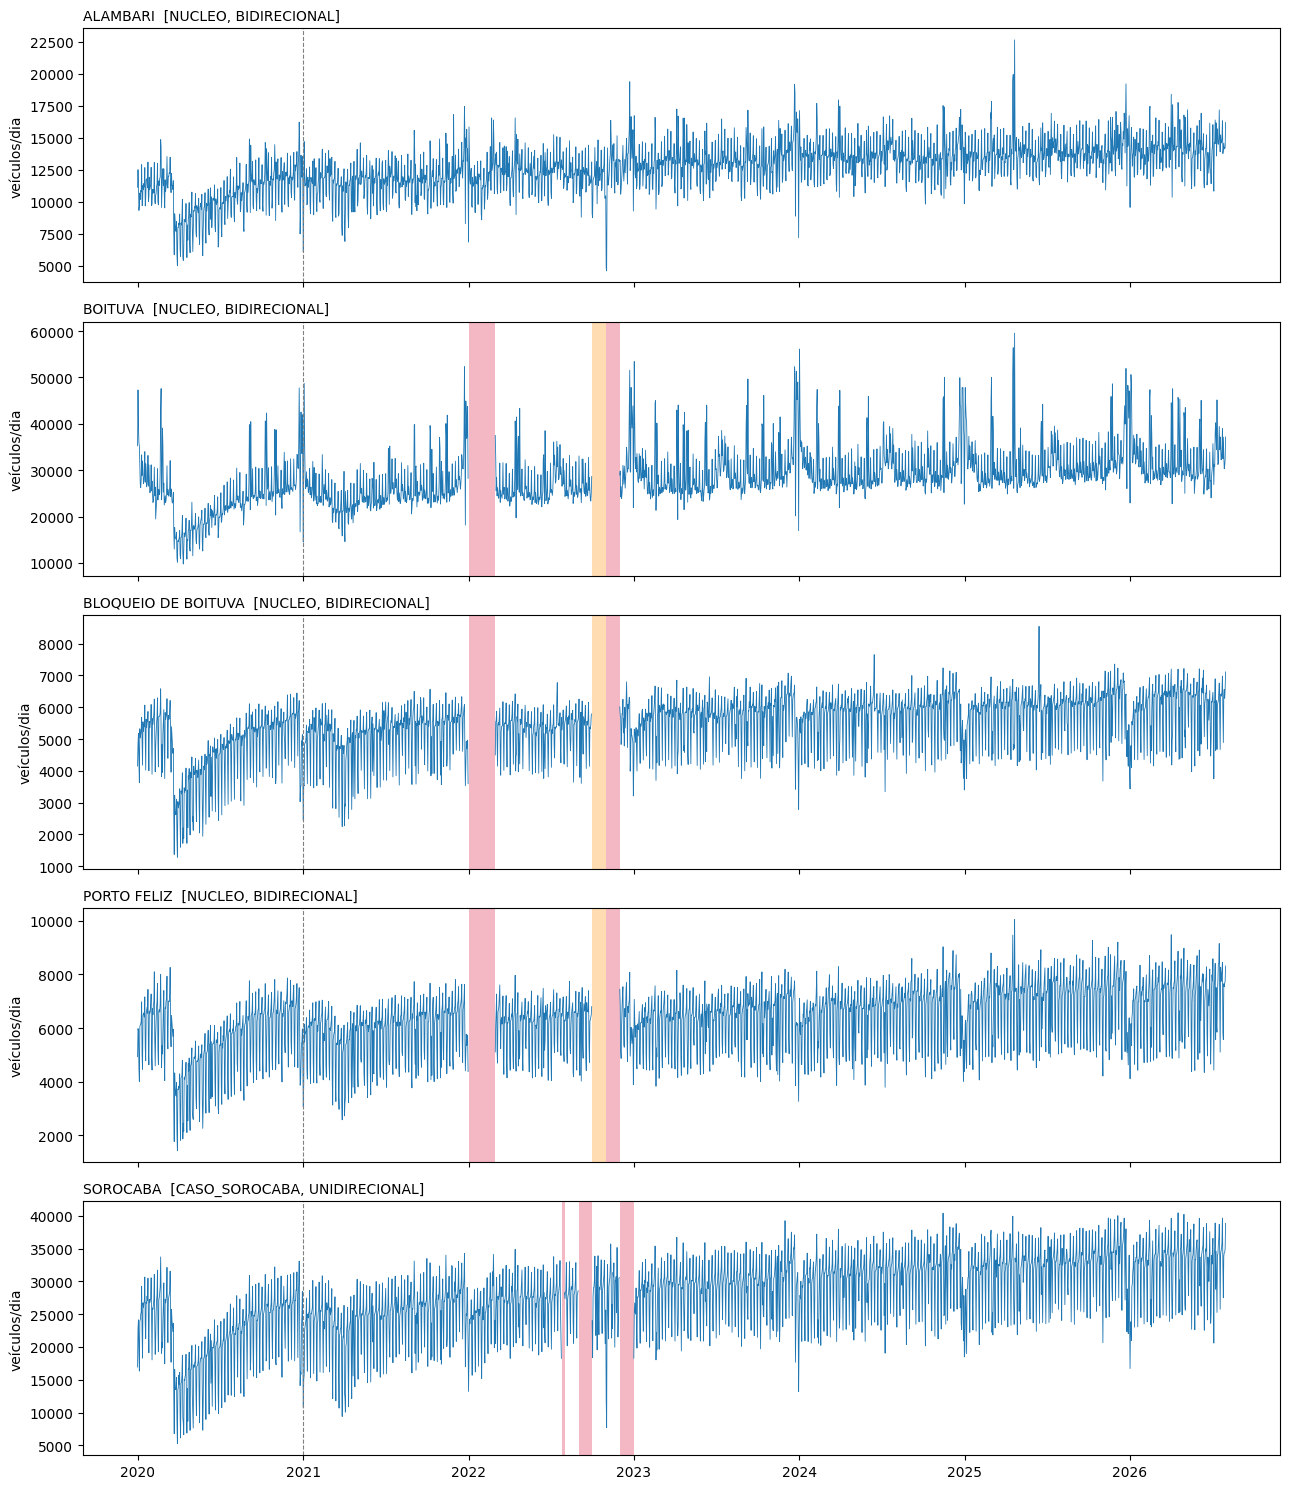

In [2]:
fig, axes = plt.subplots(len(PRACAS), 1, figsize=(13, 15), sharex=True)
for ax, praca in zip(axes, PRACAS):
    sub = series[series.PRACA == praca].sort_values("DATA")
    ax.plot(sub.DATA, sub.VOLUME_TOTAL, linewidth=0.6)
    for status, cor in [("AUSENTE", "crimson"), ("INVALIDADO", "darkorange")]:
        for d in sub[sub.STATUS == status].DATA:
            ax.axvspan(d, d + pd.Timedelta(days=1), color=cor, alpha=0.3, linewidth=0)
    ax.axvline(pd.Timestamp(config.DATA_INICIO_MODELAGEM), color="gray", linestyle="--", linewidth=0.8)
    grupo = sub.GRUPO.iloc[0]; direc = sub.DIRECIONALIDADE.iloc[0]
    ax.set_title(f"{praca}  [{grupo}, {direc}]", fontsize=10, loc="left")
    ax.set_ylabel("veículos/dia")
plt.tight_layout(); plt.show()

## 2. Sazonalidade mensal, ano sobre ano

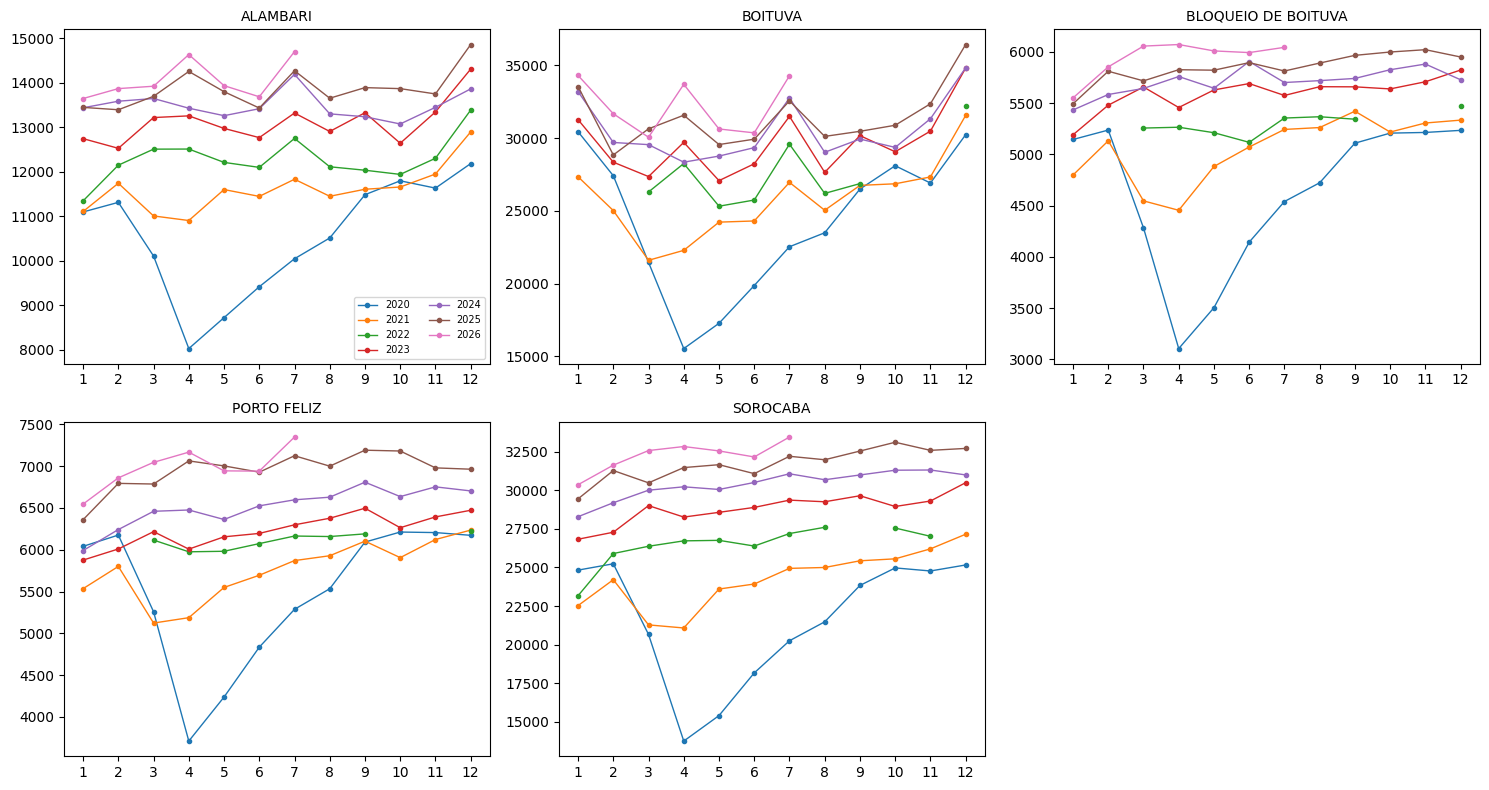

In [3]:
s = series.copy(); s["ANO"] = s.DATA.dt.year; s["MES"] = s.DATA.dt.month
mensal = s.groupby(["PRACA", "ANO", "MES"])["VOLUME_TOTAL"].mean().reset_index()
fig, axes = plt.subplots(2, 3, figsize=(15, 8)); axes = axes.flatten()
for i, praca in enumerate(PRACAS):
    sub = mensal[mensal.PRACA == praca]
    for ano in sorted(sub.ANO.unique()):
        x = sub[sub.ANO == ano].sort_values("MES")
        axes[i].plot(x.MES, x.VOLUME_TOTAL, marker="o", markersize=3, linewidth=1, label=str(ano))
    axes[i].set_title(praca, fontsize=10); axes[i].set_xticks(range(1, 13))
axes[-1].axis("off"); axes[0].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

## 3. Sazonalidade semanal

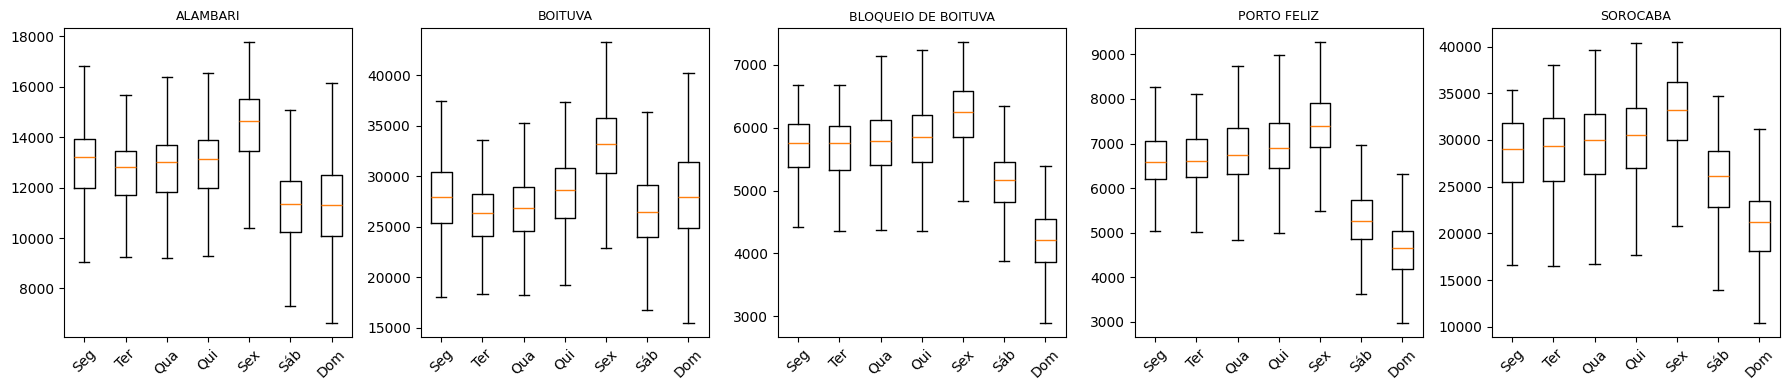

In [4]:
dias = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]
fig, axes = plt.subplots(1, len(PRACAS), figsize=(18, 4))
for ax, praca in zip(axes, PRACAS):
    sub = series[(series.PRACA == praca) & (series.STATUS == "OK")]
    dados = [sub[sub.DATA.dt.dayofweek == d].VOLUME_TOTAL.values for d in range(7)]
    ax.boxplot(dados, tick_labels=dias, showfliers=False)
    ax.set_title(praca, fontsize=9); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

## 4. Composição por categoria de veículo (leve, moto, pesado)

Rastreabilidade por grupo de eixos: o modelo usa o total, mas a composição continua
disponível nas colunas `VOLUME_LEVE`, `VOLUME_MOTO` e `VOLUME_PESADO`.

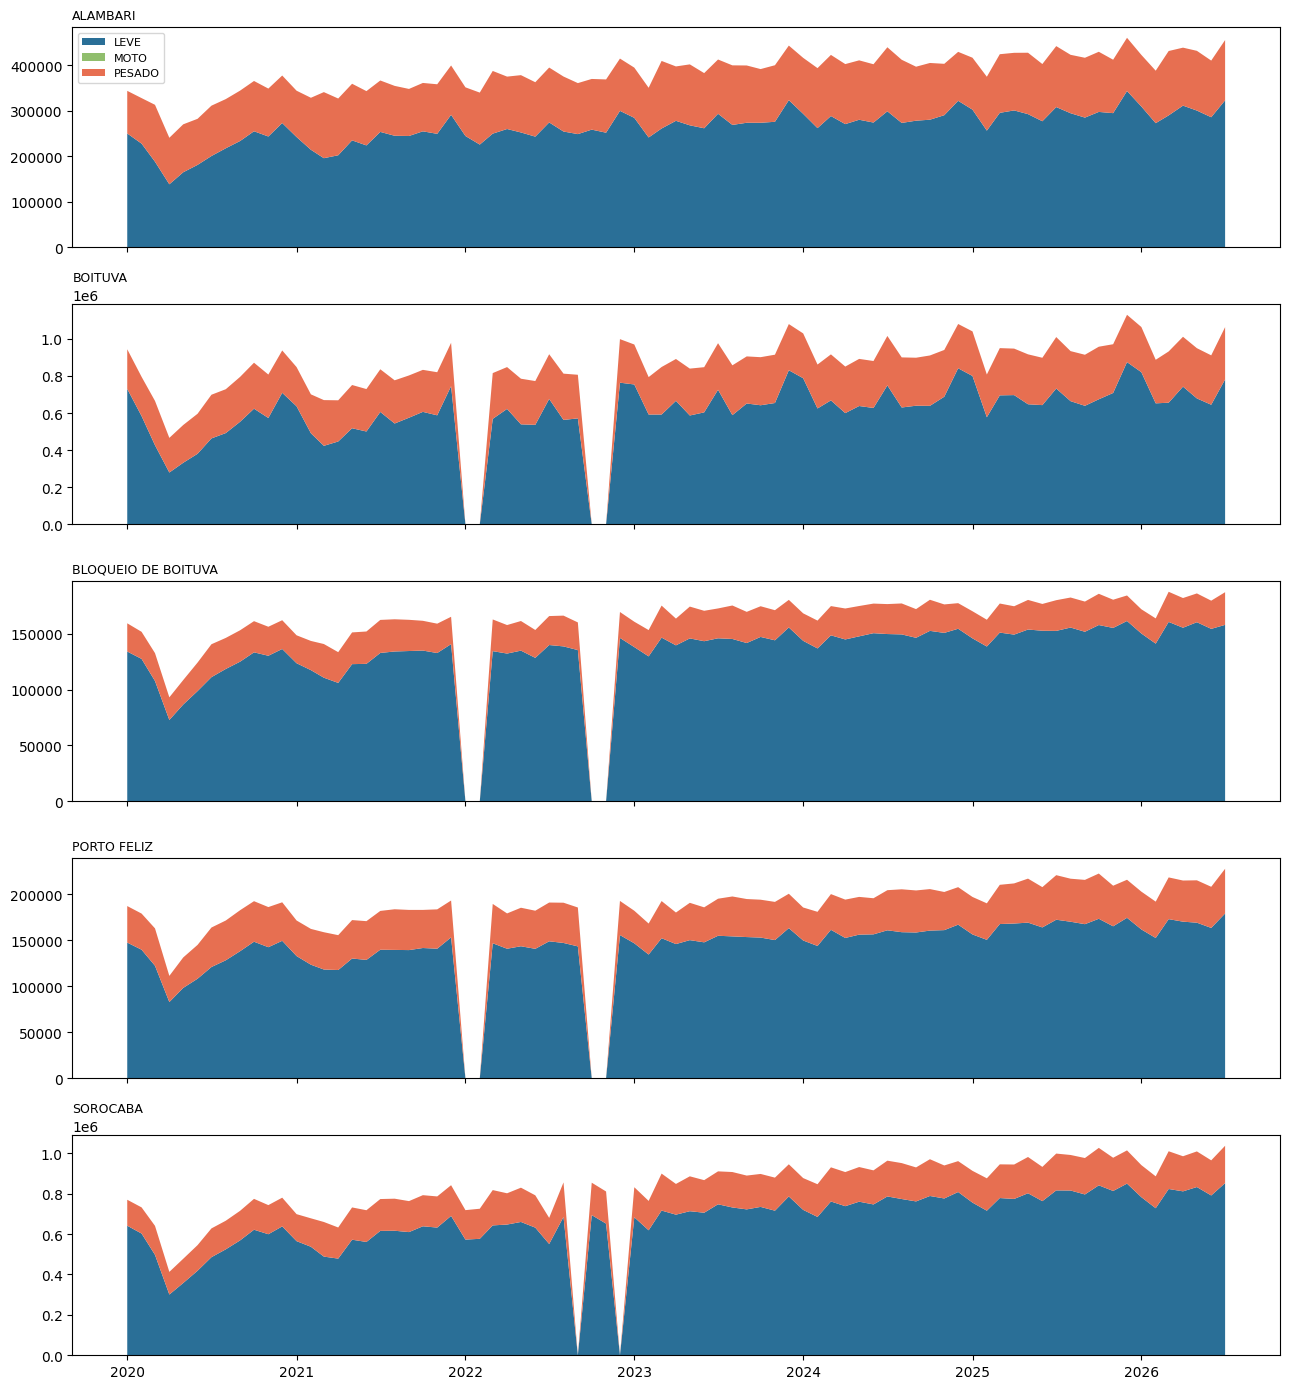

In [5]:
fig, axes = plt.subplots(len(PRACAS), 1, figsize=(13, 14), sharex=True)
cores = {"VOLUME_LEVE": "#2a6f97", "VOLUME_MOTO": "#90be6d", "VOLUME_PESADO": "#e76f51"}
for ax, praca in zip(axes, PRACAS):
    sub = series[series.PRACA == praca].set_index("DATA")[list(cores)].resample("MS").sum()
    ax.stackplot(sub.index, sub.values.T, labels=[c.replace("VOLUME_", "") for c in cores], colors=list(cores.values()))
    ax.set_title(praca, fontsize=9, loc="left")
axes[0].legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

## 5. Comparação dos modelos

Só aparece depois de rodar `python modelo_ingenuo.py`, `python arima_baseline.py` e `python comparar_modelos.py`. MAPE médio sobre as várias datas de partida dentro do teste (30% finais). `PCT_ORIGENS_VENCE_INGENUO` = em quantas datas o modelo errou menos que repetir a última semana.

In [6]:
caminho = Path("resultados/comparacao_modelos.csv")
if caminho.exists():
    comp = pd.read_csv(caminho)
    display(comp.pivot_table(index=["GRUPO", "PRACA", "DIAS"], columns="MODELO", values="MAPE").round(1))
    display(comp[comp.MODELO != "INGENUO"][["MODELO", "PRACA", "DIAS", "MAPE", "PCT_ORIGENS_VENCE_INGENUO"]])
else:
    print("Ainda não há resultados. Rode modelo_ingenuo.py, arima_baseline.py e comparar_modelos.py")

MODELO                                  ARIMA  INGENUO
GRUPO         PRACA               DIAS                
CASO_SOROCABA SOROCABA            7       5.3      6.6
                                  90      5.9      7.9
                                  180     6.0      8.1
NUCLEO        ALAMBARI            7       7.0      6.9
                                  90      7.7      7.4
                                  180     7.6      7.3
              BLOQUEIO DE BOITUVA 7       5.6      6.8
                                  90      5.8      8.2
                                  180     5.7      8.3
              BOITUVA             7       9.5      9.6
                                  90     10.9     12.6
                                  180    10.5     13.0
              PORTO FELIZ         7       7.3      8.1
                                  90      8.9      9.2
                                  180     9.0      9.2

,MODELO,PRACA,DIAS,MAPE,PCT_ORIGENS_VENCE_INGENUO
0,ARIMA,ALAMBARI,7,7.04,41.4
2,ARIMA,ALAMBARI,90,7.71,24.0
4,ARIMA,ALAMBARI,180,7.63,21.0
6,ARIMA,BLOQUEIO DE BOITUVA,7,5.57,69.0
8,ARIMA,BLOQUEIO DE BOITUVA,90,5.77,73.3
10,ARIMA,BLOQUEIO DE BOITUVA,180,5.67,82.3
12,ARIMA,BOITUVA,7,9.48,31.0
14,ARIMA,BOITUVA,90,10.89,36.0
16,ARIMA,BOITUVA,180,10.51,40.3
18,ARIMA,PORTO FELIZ,7,7.31,49.4


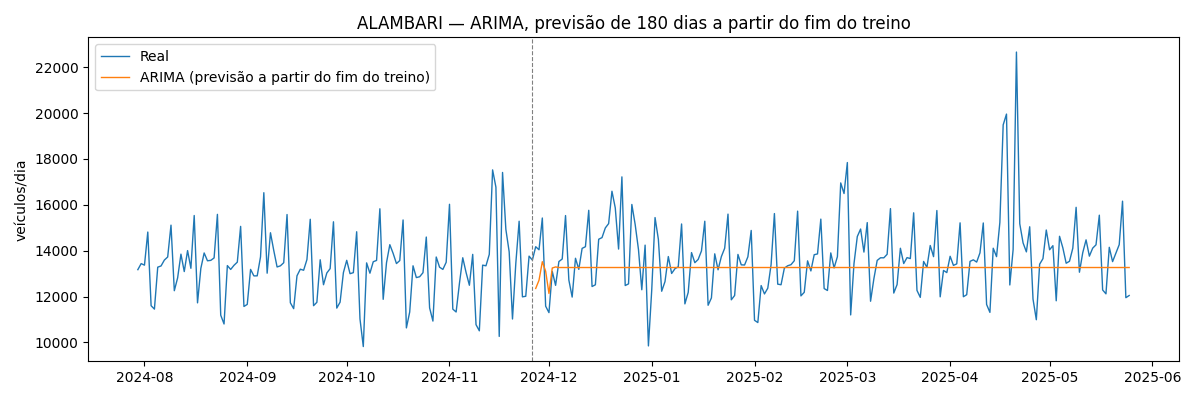

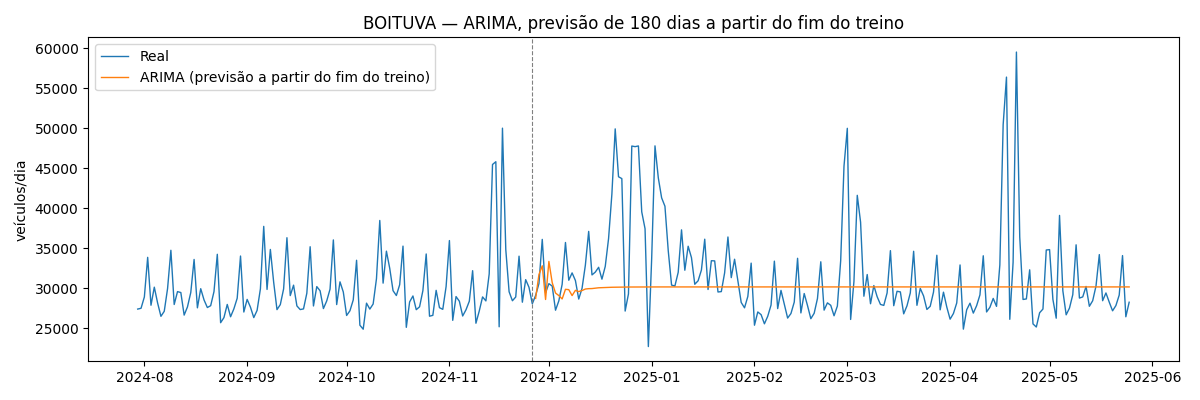

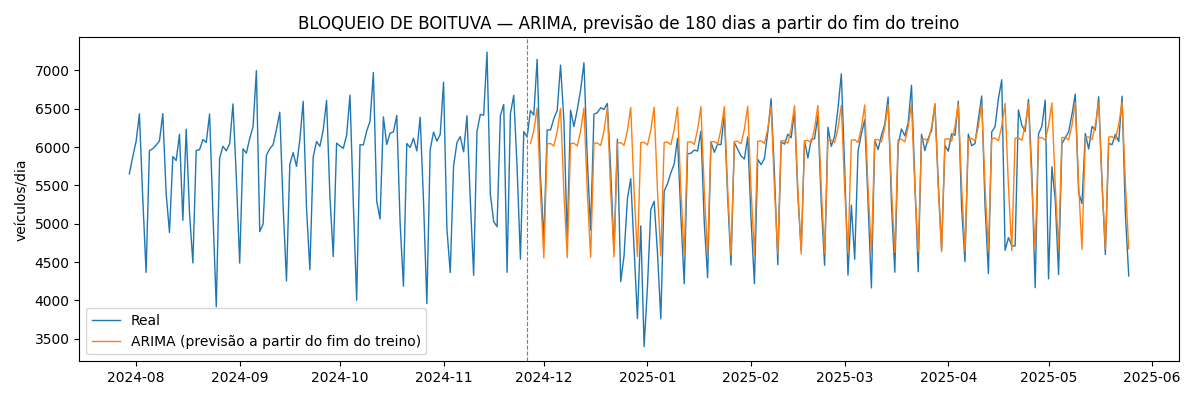

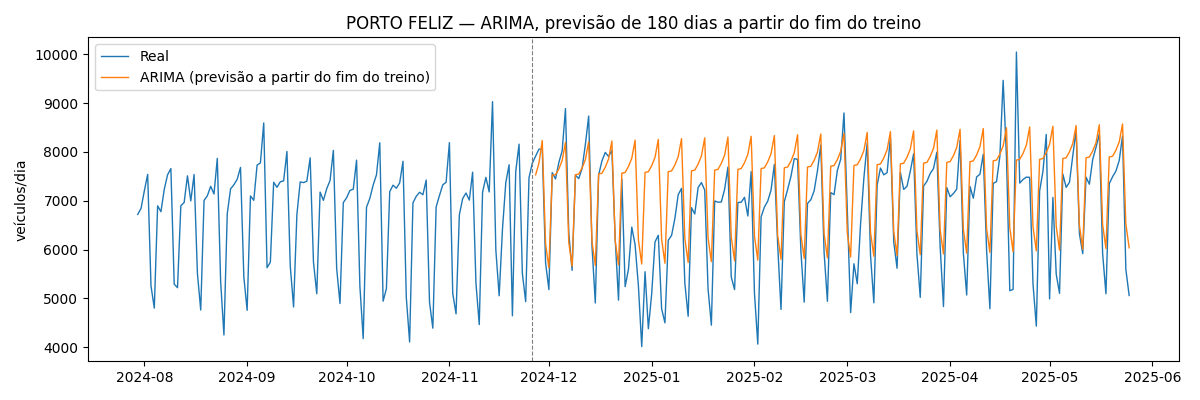

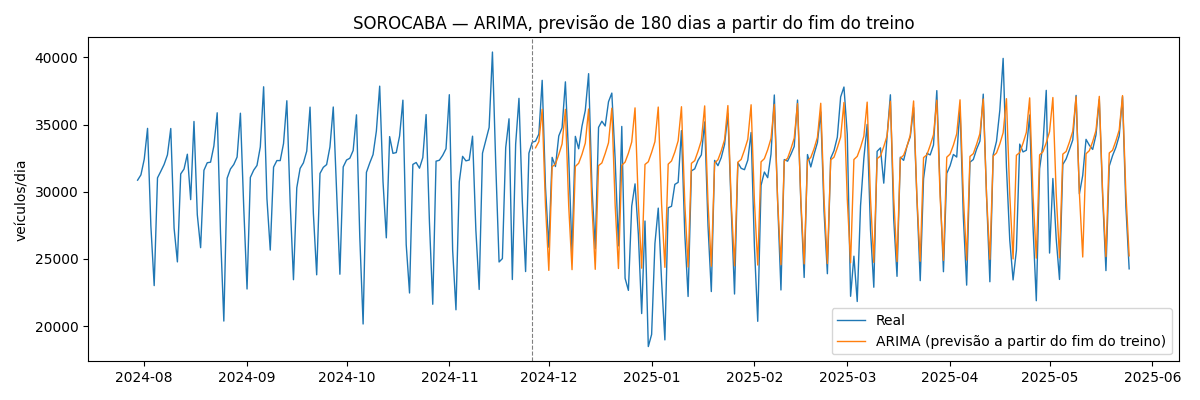

In [7]:
from IPython.display import Image, display
for praca in PRACAS:
    img = Path(f"resultados/arima_{praca.replace(' ', '_')}.png")
    if img.exists():
        display(Image(filename=str(img)))